# Manifold Hierarchical Search - CS5800

Stub notebook. Each function has a comment describing what to implement.
Fill in the bodies. Structure follows the project outline.


## 1) Imports

In [1]:
import numpy as np
import heapq
import time
import matplotlib.pyplot as plt
import os
from collections import deque

# plots are saved here (created if missing), alongside the notebook
IMG_DIR = 'images'
os.makedirs(IMG_DIR, exist_ok=True)


## 2) Manifold generators

Each generator returns a graph. Agreed shared format:
- `coords`: dict vertex_id -> (x, y, z) position in 3D
- `adj`: dict vertex_id -> list of neighbor vertex_ids

Everything downstream only touches `coords` and `adj`.


In [2]:
def make_sphere_grid(n_lat, n_lon):
    # place points on a lat-lon grid on the unit sphere
    # vertex id = i * n_lon + j  (row-major)
    coords = {}
    adj = {}

    def vid(i, j):
        return i * n_lon + j

    for i in range(n_lat):
        # polar angle: (i+0.5) keeps rows off the exact poles, so no
        # degenerate duplicate points and every row has n_lon distinct vertices
        theta = np.pi * (i + 0.5) / n_lat
        for j in range(n_lon):
            phi = 2.0 * np.pi * j / n_lon          # azimuth
            x = np.sin(theta) * np.cos(phi)
            y = np.sin(theta) * np.sin(phi)
            z = np.cos(theta)
            coords[vid(i, j)] = (x, y, z)

    for i in range(n_lat):
        for j in range(n_lon):
            nbrs = []
            if i > 0:
                nbrs.append(vid(i - 1, j))         # up   (no wrap across poles)
            if i < n_lat - 1:
                nbrs.append(vid(i + 1, j))         # down
            nbrs.append(vid(i, (j - 1) % n_lon))   # left  (wrap longitude)
            nbrs.append(vid(i, (j + 1) % n_lon))   # right (wrap longitude)
            adj[vid(i, j)] = nbrs

    return coords, adj


In [3]:
def make_torus_grid(n_rows, n_cols, R=2.0, r=1.0):
    # place points on a torus surface (R = center-to-tube radius, r = tube radius)
    # grid neighbors wrap BOTH directions (top-bottom and left-right)
    # vertex id = i * n_cols + j  (row-major)
    coords = {}
    adj = {}

    def vid(i, j):
        return i * n_cols + j

    for i in range(n_rows):
        u = 2.0 * np.pi * i / n_rows           # angle around the central hole
        for j in range(n_cols):
            v = 2.0 * np.pi * j / n_cols       # angle around the tube
            x = (R + r * np.cos(v)) * np.cos(u)
            y = (R + r * np.cos(v)) * np.sin(u)
            z = r * np.sin(v)
            coords[vid(i, j)] = (x, y, z)

    for i in range(n_rows):
        for j in range(n_cols):
            adj[vid(i, j)] = [
                vid((i - 1) % n_rows, j),      # up    (wrap)
                vid((i + 1) % n_rows, j),      # down  (wrap)
                vid(i, (j - 1) % n_cols),      # left  (wrap)
                vid(i, (j + 1) % n_cols),      # right (wrap)
            ]

    return coords, adj

In [4]:
def edge_length(coords, u, v):
    # euclidean distance between two vertex positions
    # used as edge weight for Dijkstra / hierarchical search
    (ux, uy, uz), (vx, vy, vz) = coords[u], coords[v]
    return ((ux - vx) ** 2 + (uy - vy) ** 2 + (uz - vz) ** 2) ** 0.5

## 2b) Visualize the manifolds

Draw the graph in 3D so we can see the surface we search over.
Vertices are points, gray lines are edges. Saved to images/ for the report.


In [5]:
def visualize_manifold(coords, adj, title, fname=None, elev=25, azim=45):
    fig = plt.figure(figsize=(6, 5))
    ax = fig.add_subplot(111, projection='3d')
    # edges: draw each once (v > u avoids duplicates)
    for u, nbrs in adj.items():
        xu, yu, zu = coords[u]
        for v in nbrs:
            if v > u:
                xv, yv, zv = coords[v]
                ax.plot([xu, xv], [yu, yv], [zu, zv], color='0.6', lw=0.4, alpha=0.6)
    # vertices
    P = np.array([coords[k] for k in coords])
    ax.scatter(P[:, 0], P[:, 1], P[:, 2], s=6, color='tab:blue')
    ax.set_title(title); ax.set_box_aspect([1, 1, 1])
    ax.view_init(elev=elev, azim=azim)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    if fname:
        plt.savefig(os.path.join(IMG_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()


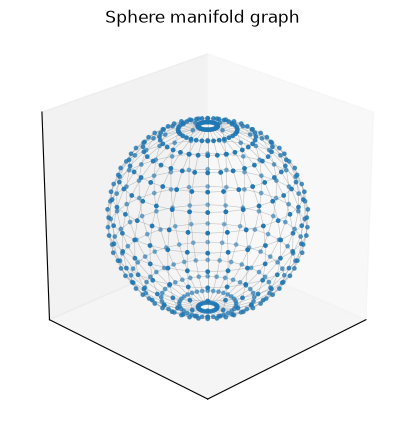

In [6]:
cs, as_ = make_sphere_grid(16, 32)
visualize_manifold(cs, as_, "Sphere manifold graph", "manifold_sphere.png")


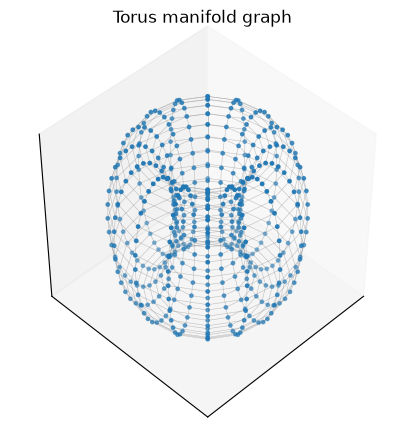

In [7]:
ct, at_ = make_torus_grid(16, 32)
visualize_manifold(ct, at_, "Torus manifold graph", "manifold_torus.png", elev=45)


## 3) Ground truth (sphere only)

True geodesic on the unit sphere = great-circle distance.
Used to measure how wrong each algorithm's path length is.


In [8]:
def sphere_geodesic(p, q):
    # great-circle distance between two unit-sphere points
    # arccos of the dot product (clip to [-1, 1] to stay in arccos domain)
    dot = p[0] * q[0] + p[1] * q[1] + p[2] * q[2]
    return float(np.arccos(np.clip(dot, -1.0, 1.0)))

## 4) Algorithms

Baselines first, then the partition structure and hierarchical search.


In [9]:
def bfs(adj, source):
    # unweighted hop distance from source to all reachable vertices
    # returns dict vertex -> hop count
    dist = {source: 0}
    dq = deque([source])
    while dq:
        u = dq.popleft()
        for w in adj[u]:
            if w not in dist:
                dist[w] = dist[u] + 1
                dq.append(w)
    return dist

In [10]:
def dijkstra(coords, adj, source, target=None):
    # weighted shortest path, edge weights = edge_length. EXACT baseline.
    # target=None  -> returns dist dict (vertex -> shortest distance from source)
    # target given -> returns (distance_to_target, path as vertex list)
    dist = {source: 0.0}
    prev = {}
    pq = [(0.0, source)]
    visited = set()
    while pq:
        d, u = heapq.heappop(pq)
        if u in visited:
            continue
        visited.add(u)
        if target is not None and u == target:
            break
        for w in adj[u]:
            nd = d + edge_length(coords, u, w)
            if nd < dist.get(w, float('inf')):
                dist[w] = nd
                prev[w] = u
                heapq.heappush(pq, (nd, w))

    if target is None:
        return dist
    if target not in dist:
        return float('inf'), []
    path = [target]
    while path[-1] != source:
        path.append(prev[path[-1]])
    path.reverse()
    return dist[target], path

In [11]:
def astar(coords, adj, source, target):
    # A* with a straight-line 3D heuristic. The heuristic is the Euclidean
    # distance to the target, which never exceeds the true remaining path
    # length (edges are Euclidean), so it is admissible and A* stays exact.
    def h(u):
        return edge_length(coords, u, target)
    dist = {source: 0.0}
    prev = {}
    pq = [(h(source), 0.0, source)]
    seen = set()
    while pq:
        f, dcur, u = heapq.heappop(pq)
        if u in seen:
            continue
        seen.add(u)
        if u == target:
            break
        for w in adj[u]:
            nd = dcur + edge_length(coords, u, w)
            if nd < dist.get(w, float('inf')):
                dist[w] = nd
                prev[w] = u
                heapq.heappush(pq, (nd + h(w), nd, w))
    if target not in dist:
        return float('inf'), []
    path = [target]
    while path[-1] != source:
        path.append(prev[path[-1]])
    path.reverse()
    return dist[target], path


In [12]:
def _multi_source_bfs(adj, seeds):
    # grow BFS frontiers from all seeds at once; each vertex is claimed by the
    # seed that reaches it first (a graph-Voronoi assignment by hop distance)
    dist = {}
    owner = {}
    dq = deque()
    for s in seeds:
        dist[s] = 0
        owner[s] = s
        dq.append(s)
    while dq:
        u = dq.popleft()
        for w in adj[u]:
            if w not in dist:
                dist[w] = dist[u] + 1
                owner[w] = owner[u]
                dq.append(w)
    return dist, owner


def partition(coords, adj, n_patches):
    # split the graph into patches (regions)
    # seeds are chosen by farthest-point sampling (spread out for balanced patches),
    # then every vertex is assigned to its nearest seed via multi-source BFS.
    # returns: patch_of[vertex] -> patch_id, and patch adjacency (patch -> set of touching patches)
    vertices = list(adj.keys())
    n_patches = min(n_patches, len(vertices))

    seeds = [vertices[0]]
    while len(seeds) < n_patches:
        dist, _ = _multi_source_bfs(adj, seeds)
        # next seed = the vertex farthest from every existing seed
        nxt = max(vertices, key=lambda v: dist.get(v, 0))
        if dist.get(nxt, 0) == 0:
            break                                  # no vertex left to separate
        seeds.append(nxt)

    _, owner = _multi_source_bfs(adj, seeds)
    seed_id = {s: i for i, s in enumerate(seeds)}
    patch_of = {v: seed_id[owner[v]] for v in vertices}

    patch_adj = {i: set() for i in range(len(seeds))}
    for u in vertices:
        for w in adj[u]:
            if patch_of[u] != patch_of[w]:
                patch_adj[patch_of[u]].add(patch_of[w])
                patch_adj[patch_of[w]].add(patch_of[u])

    return patch_of, patch_adj

In [13]:
def build_patch_graph(coords, adj, patch_of):
    # precompute a coarse graph over patches -- the manifold DATA STRUCTURE.
    # nodes = patches; each patch keeps a representative vertex (closest to its centroid).
    # edges = patches that touch, weight = straight-line distance between representatives.
    # returned dict: members[p]=vertices, rep[p]=representative vertex, edges[p]={q: weight}
    members = {}
    for v, p in patch_of.items():
        members.setdefault(p, []).append(v)

    rep = {}
    for p, verts in members.items():
        cx = np.mean([coords[v][0] for v in verts])
        cy = np.mean([coords[v][1] for v in verts])
        cz = np.mean([coords[v][2] for v in verts])
        rep[p] = min(
            verts,
            key=lambda v: (coords[v][0] - cx) ** 2
            + (coords[v][1] - cy) ** 2
            + (coords[v][2] - cz) ** 2,
        )

    edges = {p: {} for p in members}
    for u in patch_of:
        for w in adj[u]:
            pu, pw = patch_of[u], patch_of[w]
            if pu != pw:
                d = edge_length(coords, rep[pu], rep[pw])
                edges[pu][pw] = d
                edges[pw][pu] = d

    return {'members': members, 'rep': rep, 'edges': edges}

In [14]:
def hierarchical_search(coords, adj, patch_of, patch_graph, source, target):
    # two-level search:
    #   1. route coarsely at the patch level (Dijkstra over the small patch graph)
    #   2. refine with a fine Dijkstra restricted to the "corridor" of patches on that route
    # This expands far fewer vertices than flat Dijkstra, but the corridor may not
    # contain the true shortest path -> approximate. returns (length, path).
    edges = patch_graph['edges']
    members = patch_graph['members']
    ps, pt = patch_of[source], patch_of[target]

    def patch_route(ps, pt):
        # Dijkstra on the coarse patch graph; returns list of patch ids ps..pt
        dist = {ps: 0.0}
        prev = {}
        pq = [(0.0, ps)]
        seen = set()
        while pq:
            d, p = heapq.heappop(pq)
            if p in seen:
                continue
            seen.add(p)
            if p == pt:
                break
            for q, w in edges[p].items():
                nd = d + w
                if nd < dist.get(q, float('inf')):
                    dist[q] = nd
                    prev[q] = p
                    heapq.heappush(pq, (nd, q))
        if pt not in dist:
            return None
        route = [pt]
        while route[-1] != ps:
            route.append(prev[route[-1]])
        route.reverse()
        return route

    route = patch_route(ps, pt)
    if route is None:                              # patches disconnected -> exact fallback
        return dijkstra(coords, adj, source, target)

    allowed = set()
    for p in route:
        allowed.update(members[p])

    # fine Dijkstra confined to the corridor vertices
    dist = {source: 0.0}
    prev = {}
    pq = [(0.0, source)]
    seen = set()
    while pq:
        d, u = heapq.heappop(pq)
        if u in seen:
            continue
        seen.add(u)
        if u == target:
            break
        for w in adj[u]:
            if w not in allowed:
                continue
            nd = d + edge_length(coords, u, w)
            if nd < dist.get(w, float('inf')):
                dist[w] = nd
                prev[w] = u
                heapq.heappush(pq, (nd, w))

    if target not in dist:                         # corridor didn't connect -> exact fallback
        return dijkstra(coords, adj, source, target)

    path = [target]
    while path[-1] != source:
        path.append(prev[path[-1]])
    path.reverse()
    return dist[target], path

## 5) Main run

Wire it together: build a manifold, run each algorithm, collect numbers.


In [15]:
# build one manifold to sanity-check everything runs
coords, adj = make_sphere_grid(n_lat=20, n_lon=40)

source = 0
target = len(coords) - 1  # last vertex (bottom row, last longitude)

# exact baseline
d_exact, path_exact = dijkstra(coords, adj, source, target)

# our structure
patch_of, _ = partition(coords, adj, n_patches=8)
pg = build_patch_graph(coords, adj, patch_of)
d_approx, path_approx = hierarchical_search(coords, adj, patch_of, pg, source, target)

# ground truth
d_true = sphere_geodesic(coords[source], coords[target])

print(f"exact Dijkstra : {d_exact:.4f}  ({len(path_exact)} vertices)")
print(f"hierarchical   : {d_approx:.4f}  ({len(path_approx)} vertices)")
print(f"geodesic truth : {d_true:.4f}")
print(f"Dijkstra rel. error vs geodesic : {abs(d_exact - d_true) / d_true:.2%}")
print(f"hierarchical rel. error vs geodesic : {abs(d_approx - d_true) / d_true:.2%}")
print(f"hierarchical overhead vs exact graph dist : {abs(d_approx - d_exact) / d_exact:.2%}")

exact Dijkstra : 2.9938  (21 vertices)
hierarchical   : 2.9938  (21 vertices)
geodesic truth : 2.9850
Dijkstra rel. error vs geodesic : 0.29%
hierarchical rel. error vs geodesic : 0.29%
hierarchical overhead vs exact graph dist : 0.00%


In [16]:
import random

def benchmark(generator, sizes, n_queries=30, has_ground_truth=False, seed=1):
    # generator(n) -> (coords, adj). sizes are the size parameter n (n_lon/n_cols = 2*n).
    # Each metric is AVERAGED over n_queries random source/target pairs per size,
    # so a single unlucky corridor no longer dominates a data point.
    #
    # partition + build_patch_graph are one-time preprocessing of the data structure,
    # excluded from per-query timing (amortized over many queries).
    #
    # metrics:
    #   *_times        : mean flat-Dijkstra and hierarchical QUERY time
    #   hier_overhead  : mean (hier_len - exact_len)/exact_len  -- works on ANY manifold
    #   *_geo_error    : mean error vs true geodesic, sphere only (has_ground_truth=True)
    rng = random.Random(seed)
    R = {'V': [], 'dijkstra_times': [], 'hier_times': [], 'hier_overhead': [],
         'dijkstra_geo_error': [], 'hier_geo_error': []}

    for n in sizes:
        coords, adj = generator(n)
        V = len(coords)
        verts = list(adj.keys())

        n_patches = max(4, int(np.sqrt(V)))          # preprocessing (not timed)
        patch_of, _ = partition(coords, adj, n_patches)
        pg = build_patch_graph(coords, adj, patch_of)

        td = th = ov = dg = hg = 0.0
        for _ in range(n_queries):
            s = rng.choice(verts)
            t = rng.choice(verts)
            while t == s:
                t = rng.choice(verts)

            t0 = time.perf_counter()
            d_exact, _ = dijkstra(coords, adj, s, t)
            td += time.perf_counter() - t0

            t0 = time.perf_counter()
            d_approx, _ = hierarchical_search(coords, adj, patch_of, pg, s, t)
            th += time.perf_counter() - t0

            ov += (d_approx - d_exact) / d_exact
            if has_ground_truth:
                d_true = sphere_geodesic(coords[s], coords[t])
                dg += abs(d_exact - d_true) / d_true
                hg += abs(d_approx - d_true) / d_true

        R['V'].append(V)
        R['dijkstra_times'].append(td / n_queries)
        R['hier_times'].append(th / n_queries)
        R['hier_overhead'].append(ov / n_queries)
        R['dijkstra_geo_error'].append(dg / n_queries if has_ground_truth else None)
        R['hier_geo_error'].append(hg / n_queries if has_ground_truth else None)

        tag = (f"  geoErr Dij={dg/n_queries:6.2%} Hier={hg/n_queries:6.2%}"
               if has_ground_truth else "")
        print(f"V={V:5d} | Dij {td/n_queries*1e3:6.2f} ms  Hier {th/n_queries*1e3:6.2f} ms"
              f" | hier overhead {ov/n_queries:6.2%}{tag}")

    return R


## 6) Results

Sphere and torus, each averaged over many random queries.
- Speed: hierarchical vs flat Dijkstra on both manifolds.
- Sphere accuracy: error vs true geodesic (ground truth available).
- Torus accuracy: no closed-form geodesic, so we measure hierarchical overhead vs exact Dijkstra a universal metric shown for both.


In [ ]:
# size parameter n; grid is n x 2n. sphere uses lat-lon, torus wraps both ways.
sizes = [8, 12, 16, 20, 28, 40]

print("SPHERE (has geodesic ground truth)")
res_sphere = benchmark(lambda n: make_sphere_grid(n, 2 * n),
                       sizes, n_queries=30, has_ground_truth=True)

print("\nTORUS (no closed-form geodesic -> accuracy = overhead vs exact Dijkstra)")
res_torus = benchmark(lambda n: make_torus_grid(n, 2 * n),
                      sizes, n_queries=30, has_ground_truth=False)


SPHERE (has geodesic ground truth)
V=  128 | Dij   0.16 ms  Hier   0.06 ms | hier overhead 19.64%  geoErr Dij=11.11% Hier=32.55%
V=  288 | Dij   0.30 ms  Hier   0.09 ms | hier overhead 11.46%  geoErr Dij= 7.80% Hier=20.09%
V=  512 | Dij   0.66 ms  Hier   0.15 ms | hier overhead 12.72%  geoErr Dij=10.37% Hier=24.08%
V=  800 | Dij   0.91 ms  Hier   0.19 ms | hier overhead 11.02%  geoErr Dij=11.64% Hier=23.77%
V= 1568 | Dij   1.37 ms  Hier   0.26 ms | hier overhead 13.46%  geoErr Dij=12.61% Hier=27.53%
V= 3200 | Dij   4.69 ms  Hier   0.60 ms | hier overhead 14.97%  geoErr Dij= 9.46% Hier=25.52%

TORUS (no closed-form geodesic -> accuracy = overhead vs exact Dijkstra)
V=  128 | Dij   0.14 ms  Hier   0.05 ms | hier overhead 29.05%
V=  288 | Dij   0.34 ms  Hier   0.08 ms | hier overhead 15.71%
V=  512 | Dij   0.86 ms  Hier   0.15 ms | hier overhead 23.26%
V=  800 | Dij   0.83 ms  Hier   0.18 ms | hier overhead 38.51%
V= 1568 | Dij   2.06 ms  Hier   0.26 ms | hier overhead 26.26%
V= 3200 | Di

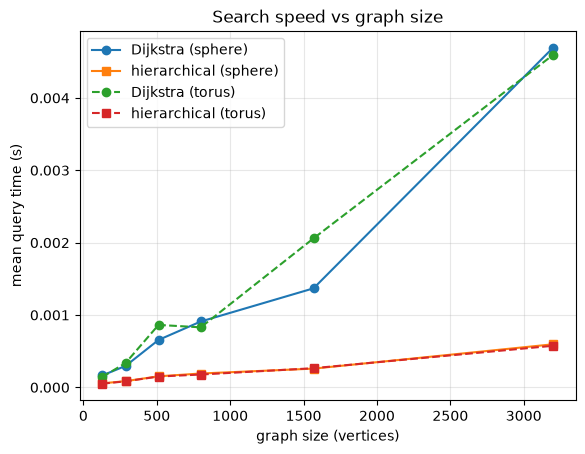

In [18]:
# Speed vs graph size -- both manifolds, both algorithms
plt.figure()
plt.plot(res_sphere['V'], res_sphere['dijkstra_times'], 'o-',  label='Dijkstra (sphere)')
plt.plot(res_sphere['V'], res_sphere['hier_times'],     's-',  label='hierarchical (sphere)')
plt.plot(res_torus['V'],  res_torus['dijkstra_times'],  'o--', label='Dijkstra (torus)')
plt.plot(res_torus['V'],  res_torus['hier_times'],      's--', label='hierarchical (torus)')
plt.xlabel('graph size (vertices)'); plt.ylabel('mean query time (s)')
plt.title('Search speed vs graph size')
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(IMG_DIR, 'speed_vs_size.png'), dpi=150, bbox_inches='tight')
plt.show()


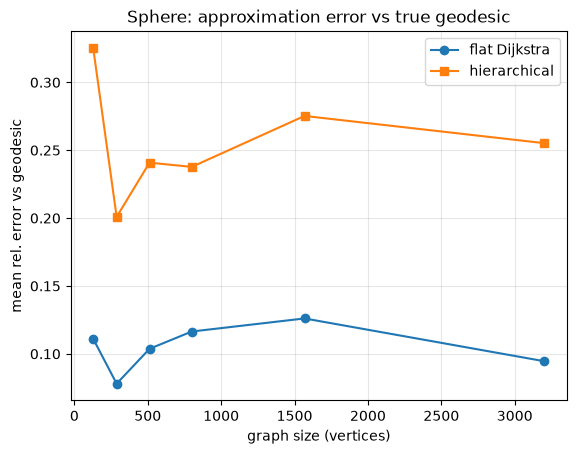

In [19]:
# Accuracy vs geodesic ground truth -- SPHERE only
plt.figure()
plt.plot(res_sphere['V'], res_sphere['dijkstra_geo_error'], 'o-', label='flat Dijkstra')
plt.plot(res_sphere['V'], res_sphere['hier_geo_error'],     's-', label='hierarchical')
plt.xlabel('graph size (vertices)'); plt.ylabel('mean rel. error vs geodesic')
plt.title('Sphere: approximation error vs true geodesic')
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(IMG_DIR, 'sphere_geodesic_error.png'), dpi=150, bbox_inches='tight')
plt.show()


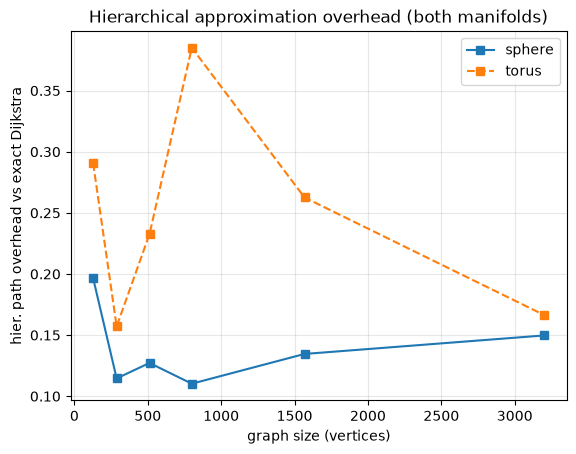

In [20]:
# Universal accuracy metric that works on BOTH manifolds:
# how much longer is the hierarchical path than exact Dijkstra?
plt.figure()
plt.plot(res_sphere['V'], res_sphere['hier_overhead'], 's-',  label='sphere')
plt.plot(res_torus['V'],  res_torus['hier_overhead'],  's--', label='torus')
plt.xlabel('graph size (vertices)'); plt.ylabel('hier. path overhead vs exact Dijkstra')
plt.title('Hierarchical approximation overhead (both manifolds)')
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(IMG_DIR, 'hierarchical_overhead.png'), dpi=150, bbox_inches='tight')
plt.show()


## 7) Tables

Build LaTeX tables straight from the results so the paper matches the run.
Saved to tables/ ; \input them in Overleaf.


In [21]:
os.makedirs('tables', exist_ok=True)

def _pct(x):
    return '--' if x is None else f'{x*100:.1f}\\%'

def speed_table(rs, rt):
    rows = []
    for i, V in enumerate(rs['V']):
        ds, hs = rs['dijkstra_times'][i]*1e3, rs['hier_times'][i]*1e3
        dt, ht = rt['dijkstra_times'][i]*1e3, rt['hier_times'][i]*1e3
        rows.append(f'{V} & {ds:.2f} & {hs:.2f} & {ds/hs:.1f}$\\times$ & {dt:.2f} & {ht:.2f} \\\\')
    header = [
        r'\begin{table}[t]', r'\centering',
        r'\caption{Mean query time (ms) and speedup of hierarchical search over flat Dijkstra.}',
        r'\label{tab:speed}',
        r'\begin{tabular}{r rr r rr}', r'\toprule',
        r' & \multicolumn{3}{c}{Sphere} & \multicolumn{2}{c}{Torus} \\',
        r'\cmidrule(lr){2-4} \cmidrule(lr){5-6}',
        r'$V$ & Dijkstra & Hier. & Speedup & Dijkstra & Hier. \\',
        r'\midrule',
    ]
    footer = [r'\bottomrule', r'\end{tabular}', r'\end{table}']
    return '\n'.join(header + rows + footer) + '\n'

def accuracy_table(rs, rt):
    rows = []
    for i, V in enumerate(rs['V']):
        rows.append(f"{V} & {_pct(rs['dijkstra_geo_error'][i])} & {_pct(rs['hier_geo_error'][i])} "
                    f"& {_pct(rs['hier_overhead'][i])} & {_pct(rt['hier_overhead'][i])} \\\\")
    header = [
        r'\begin{table}[t]', r'\centering',
        r'\caption{Accuracy. Sphere errors are relative to the true geodesic; overhead is hierarchical path length relative to exact Dijkstra.}',
        r'\label{tab:acc}',
        r'\begin{tabular}{r rrr r}', r'\toprule',
        r' & \multicolumn{3}{c}{Sphere} & Torus \\',
        r'\cmidrule(lr){2-4} \cmidrule(lr){5-5}',
        r'$V$ & Dij. err & Hier. err & Hier. ovh & Hier. ovh \\',
        r'\midrule',
    ]
    footer = [r'\bottomrule', r'\end{tabular}', r'\end{table}']
    return '\n'.join(header + rows + footer) + '\n'

t1 = speed_table(res_sphere, res_torus)
t2 = accuracy_table(res_sphere, res_torus)
open('tables/speed_table.tex', 'w').write(t1)
open('tables/accuracy_table.tex', 'w').write(t2)
print(t1)
print(t2)


\begin{table}[t]
\centering
\caption{Mean query time (ms) and speedup of hierarchical search over flat Dijkstra.}
\label{tab:speed}
\begin{tabular}{r rr r rr}
\toprule
 & \multicolumn{3}{c}{Sphere} & \multicolumn{2}{c}{Torus} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-6}
$V$ & Dijkstra & Hier. & Speedup & Dijkstra & Hier. \\
\midrule
128 & 0.16 & 0.06 & 3.0$\times$ & 0.14 & 0.05 \\
288 & 0.30 & 0.09 & 3.5$\times$ & 0.34 & 0.08 \\
512 & 0.66 & 0.15 & 4.3$\times$ & 0.86 & 0.15 \\
800 & 0.91 & 0.19 & 4.8$\times$ & 0.83 & 0.18 \\
1568 & 1.37 & 0.26 & 5.3$\times$ & 2.06 & 0.26 \\
3200 & 4.69 & 0.60 & 7.9$\times$ & 4.59 & 0.57 \\
\bottomrule
\end{tabular}
\end{table}

\begin{table}[t]
\centering
\caption{Accuracy. Sphere errors are relative to the true geodesic; overhead is hierarchical path length relative to exact Dijkstra.}
\label{tab:acc}
\begin{tabular}{r rrr r}
\toprule
 & \multicolumn{3}{c}{Sphere} & Torus \\
\cmidrule(lr){2-4} \cmidrule(lr){5-5}
$V$ & Dij. err & Hier. err & Hier. ovh & Hi

## 8) Additional experiments

Baselines and analyses that answer common review questions: an A* baseline,
correctness checks, a patch-count sweep, preprocessing cost, and query-count stability.


**Search effort: Dijkstra vs A\***

In [22]:
# Node-counting variants: same searches, but return how many vertices were
# popped (expanded). Used only to compare search effort, not for timing.
def dijkstra_count(coords, adj, source, target):
    dist = {source: 0.0}; pq = [(0.0, source)]; seen = set(); n = 0
    while pq:
        d, u = heapq.heappop(pq)
        if u in seen: continue
        seen.add(u); n += 1
        if u == target: break
        for w in adj[u]:
            nd = d + edge_length(coords, u, w)
            if nd < dist.get(w, float('inf')):
                dist[w] = nd; heapq.heappush(pq, (nd, w))
    return dist.get(target, float('inf')), n

def astar_count(coords, adj, source, target):
    def h(u): return edge_length(coords, u, target)
    dist = {source: 0.0}; pq = [(h(source), 0.0, source)]; seen = set(); n = 0
    while pq:
        f, d, u = heapq.heappop(pq)
        if u in seen: continue
        seen.add(u); n += 1
        if u == target: break
        for w in adj[u]:
            nd = d + edge_length(coords, u, w)
            if nd < dist.get(w, float('inf')):
                dist[w] = nd; heapq.heappush(pq, (nd + h(w), nd, w))
    return dist.get(target, float('inf')), n

# average nodes expanded, Dijkstra vs A*, on one sphere
_c, _a = make_sphere_grid(20, 40)
_r = random.Random(0); _v = list(_a.keys())
_td = _ta = 0; _m = 20
for _ in range(_m):
    s = _r.choice(_v); t = _r.choice(_v)
    if s == t: continue
    _, nd = dijkstra_count(_c, _a, s, t)
    _, na = astar_count(_c, _a, s, t)
    _td += nd; _ta += na
print(f"nodes expanded (avg over {_m}): Dijkstra {_td/_m:.0f}  vs  A* {_ta/_m:.0f}")


nodes expanded (avg over 20): Dijkstra 532  vs  A* 167


**Correctness checks**

In [23]:
# Correctness checks. Two hard invariants we assert, plus one approximate
# relationship we report.
_c, _a = make_sphere_grid(20, 40)
_r = random.Random(0); _v = list(_a.keys())
_po, _pa = partition(_c, _a, max(4, int(np.sqrt(len(_c)))))
_pg = build_patch_graph(_c, _a, _po)

_worst_hier = 0.0        # (hier - exact)/exact, should stay >= 0
_worst_astar = 0.0       # |A* - Dijkstra|/Dijkstra, should be ~0
_worst_geo = 0.0         # (graphDist - geodesic)/geodesic
for _ in range(50):
    s = _r.choice(_v); t = _r.choice(_v)
    if s == t: continue
    de, _ = dijkstra(_c, _a, s, t)
    da, _ = astar(_c, _a, s, t)
    dh, _ = hierarchical_search(_c, _a, _po, _pg, s, t)
    dg = sphere_geodesic(_c[s], _c[t])
    _worst_astar = max(_worst_astar, abs(da - de) / de)
    _worst_hier = min(_worst_hier, (dh - de) / de)
    _worst_geo = min(_worst_geo, (de - dg) / dg)

# hard invariants
assert _worst_astar < 1e-9, "A* should match Dijkstra exactly"
assert _worst_hier > -1e-9, "hierarchical must not be shorter than exact"
print("PASS: A* equals Dijkstra, and hierarchical is never shorter than exact.")
# approximate: edges are chords, slightly shorter than arcs, so graph distance
# can dip a fraction below the great-circle geodesic. This is expected.
print(f"graph distance vs geodesic, most-negative gap = {_worst_geo*100:.2f}% "
      f"(small chord-vs-arc effect, not an error)")


PASS: A* equals Dijkstra, and hierarchical is never shorter than exact.
graph distance vs geodesic, most-negative gap = -0.10% (small chord-vs-arc effect, not an error)


**Patch-count sweep (fixed graph size)**

k=  4 | hier  1.64 ms | overhead   1.1%
k=  8 | hier  0.77 ms | overhead   7.5%
k= 16 | hier  0.54 ms | overhead   6.7%
k= 32 | hier  0.47 ms | overhead  10.1%
k= 64 | hier  0.28 ms | overhead  19.9%


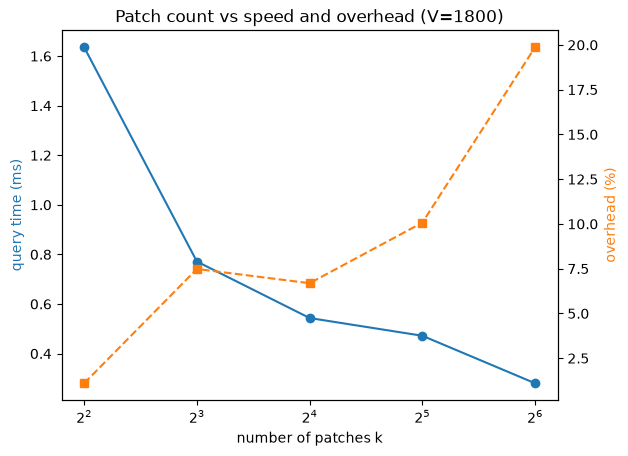

In [24]:
# Patch-count sweep at fixed graph size: how k trades speed against overhead.
_c, _a = make_sphere_grid(30, 60); _V = len(_c); _v = list(_a.keys())
_r = random.Random(3)
ks, k_time, k_ovh = [], [], []
for k in [4, 8, 16, 32, 64]:
    _po, _pa = partition(_c, _a, k); _pg = build_patch_graph(_c, _a, _po)
    th = ov = 0.0; cnt = 0
    for _ in range(20):
        s = _r.choice(_v); t = _r.choice(_v)
        if s == t: continue
        de, _ = dijkstra(_c, _a, s, t)
        t0 = time.perf_counter(); dh, _ = hierarchical_search(_c, _a, _po, _pg, s, t)
        th += time.perf_counter() - t0
        ov += (dh - de) / de; cnt += 1
    ks.append(k); k_time.append(th / cnt * 1e3); k_ovh.append(ov / cnt * 100)
    print(f"k={k:3d} | hier {k_time[-1]:5.2f} ms | overhead {k_ovh[-1]:5.1f}%")

fig, ax1 = plt.subplots()
ax1.plot(ks, k_time, 'o-', color='tab:blue'); ax1.set_xlabel('number of patches k')
ax1.set_ylabel('query time (ms)', color='tab:blue'); ax1.set_xscale('log', base=2)
ax2 = ax1.twinx(); ax2.plot(ks, k_ovh, 's--', color='tab:orange')
ax2.set_ylabel('overhead (%)', color='tab:orange')
plt.title(f'Patch count vs speed and overhead (V={_V})')
plt.savefig(os.path.join(IMG_DIR, 'patch_sweep.png'), dpi=150, bbox_inches='tight')
plt.show()


**Preprocessing cost vs graph size**

V=  128 k= 11 | preprocessing    0.9 ms
V=  512 k= 22 | preprocessing    4.8 ms
V= 1152 k= 33 | preprocessing   76.5 ms
V= 2048 k= 45 | preprocessing   45.4 ms
V= 3200 k= 56 | preprocessing   57.8 ms


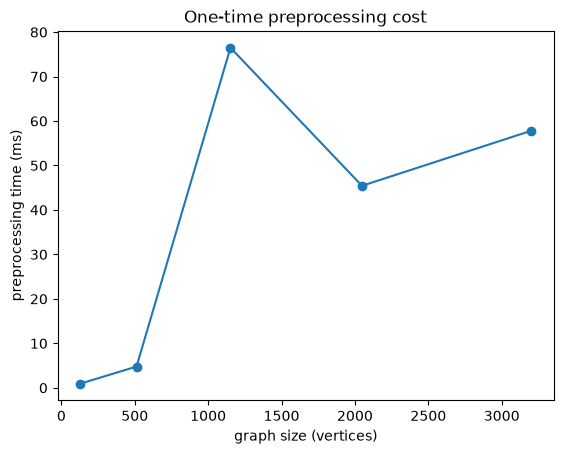

In [25]:
# Preprocessing cost vs graph size (partition + build_patch_graph only).
sizes_pp, pp_times = [], []
for n in [8, 16, 24, 32, 40]:
    _c, _a = make_sphere_grid(n, 2 * n); _V = len(_c); k = max(4, int(np.sqrt(_V)))
    t0 = time.perf_counter()
    _po, _pa = partition(_c, _a, k); _pg = build_patch_graph(_c, _a, _po)
    dt = (time.perf_counter() - t0) * 1e3
    sizes_pp.append(_V); pp_times.append(dt)
    print(f"V={_V:5d} k={k:3d} | preprocessing {dt:6.1f} ms")

plt.figure()
plt.plot(sizes_pp, pp_times, 'o-')
plt.xlabel('graph size (vertices)'); plt.ylabel('preprocessing time (ms)')
plt.title('One-time preprocessing cost')
plt.savefig(os.path.join(IMG_DIR, 'preprocessing_cost.png'), dpi=150, bbox_inches='tight')
plt.show()


**Query-count stability**

n_queries=  5 | mean overhead  16.5%
n_queries= 10 | mean overhead  16.9%
n_queries= 20 | mean overhead  19.4%
n_queries= 40 | mean overhead  15.8%
n_queries= 80 | mean overhead  16.8%
n_queries=160 | mean overhead  14.6%


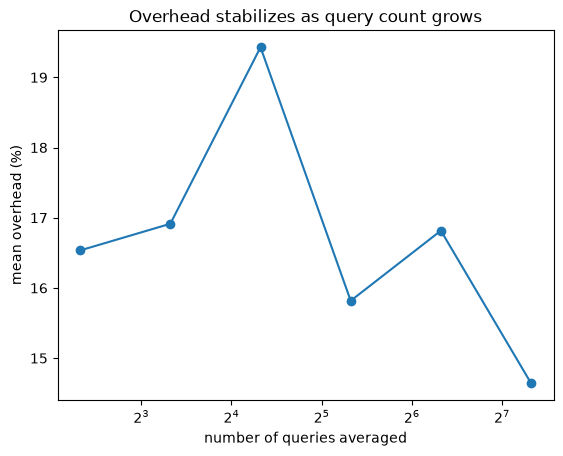

In [26]:
# Query-count stability: does mean overhead settle as we average more queries?
_c, _a = make_sphere_grid(24, 48); _v = list(_a.keys())
_po, _pa = partition(_c, _a, max(4, int(np.sqrt(len(_c))))); _pg = build_patch_graph(_c, _a, _po)
nqs, nq_ovh = [], []
for nq in [5, 10, 20, 40, 80, 160]:
    r = random.Random(7); ov = 0.0; c = 0
    for _ in range(nq):
        s = r.choice(_v); t = r.choice(_v)
        if s == t: continue
        de, _ = dijkstra(_c, _a, s, t); dh, _ = hierarchical_search(_c, _a, _po, _pg, s, t)
        ov += (dh - de) / de; c += 1
    nqs.append(nq); nq_ovh.append(ov / c * 100)
    print(f"n_queries={nq:3d} | mean overhead {nq_ovh[-1]:5.1f}%")

plt.figure()
plt.plot(nqs, nq_ovh, 'o-'); plt.xscale('log', base=2)
plt.xlabel('number of queries averaged'); plt.ylabel('mean overhead (%)')
plt.title('Overhead stabilizes as query count grows')
plt.savefig(os.path.join(IMG_DIR, 'query_stability.png'), dpi=150, bbox_inches='tight')
plt.show()
